In [1]:
import os
import json
import numpy as np
import pandas as pd
import scipy.io
import anndata as ad
from scipy.sparse import lil_matrix, issparse
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA, NMF
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE
from umap import UMAP

import torch
import torch.nn as nn
import torch.nn.functional as F
import pyliger

/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/h5sparse/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
/home/sc5625/.local/share/m

## Define helper functions

In [2]:
def as_dense(x):
    return x.toarray() if issparse(x) else np.asarray(x)

def jaccard(a, b):
    a = np.asarray(a, dtype=bool)
    b = np.asarray(b, dtype=bool)
    denom = np.logical_or(a, b).sum()
    return 0.0 if denom == 0 else np.logical_and(a, b).sum() / denom

def top_support_mask(vec, frac=0.05):
    vec = np.abs(np.asarray(vec).ravel())
    k = max(1, int(np.ceil(frac * vec.size)))
    mask = np.zeros(vec.size, dtype=bool)
    mask[np.argpartition(vec, -k)[-k:]] = True
    return mask

def edge_overlap_metrics(A_pred, A_ref, frac=0.05):
    pred = top_support_mask(A_pred, frac=frac)
    ref = top_support_mask(A_ref, frac=frac)
    tp = np.logical_and(pred, ref).sum()
    fp = pred.sum() - tp
    fn = ref.sum() - tp
    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)
    jac = tp / (pred.sum() + ref.sum() - tp + 1e-8)
    return {
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "jaccard": float(jac),
        "tp": int(tp),
        "pred_edges": int(pred.sum()),
        "ref_edges": int(ref.sum()),
    }

def mean_axis_jaccard(A_pred, A_ref, axis=0, frac=0.1):
    scores = []
    if axis == 0:  # per TF column
        for j in range(A_ref.shape[1]):
            p = top_support_mask(A_pred[:, j], frac=frac)
            r = top_support_mask(A_ref[:, j], frac=frac)
            scores.append(jaccard(p, r))
    else:  # per gene row
        for i in range(A_ref.shape[0]):
            p = top_support_mask(A_pred[i, :], frac=frac)
            r = top_support_mask(A_ref[i, :], frac=frac)
            scores.append(jaccard(p, r))
    return float(np.mean(scores)) if scores else 0.0

def module_sets_from_nmf(W, H, top_genes=25, top_tfs=15):
    # W: genes x r, H: r x tfs
    modules = []
    for k in range(W.shape[1]):
        g_idx = np.argsort(-W[:, k])[:top_genes]
        t_idx = np.argsort(-H[k, :])[:top_tfs]
        modules.append((set(g_idx.tolist()), set(t_idx.tolist())))
    return modules

def module_similarity(m1, m2):
    g1, t1 = m1
    g2, t2 = m2
    return 0.5 * jaccard(g1, g2) + 0.5 * jaccard(t1, t2)

def match_module_sets(ref_modules, cur_modules):
    S = np.array([[module_similarity(r, c) for c in cur_modules] for r in ref_modules], dtype=float)
    row_ind, col_ind = linear_sum_assignment(-S)
    matched = S[row_ind, col_ind]
    return {
        "mean_conservation": float(np.mean(matched)),
        "std_conservation": float(np.std(matched)),
        "matched_scores": matched,
        "similarity_matrix": S,
    }

def pseudotime_arrow_agreement(X_space, V_pred, pseudotime, k=30):
    """
    For each cell, find the nearest neighbor with slightly larger pseudotime
    among local neighbors, and compare that arrow with predicted velocity.
    Returns mean cosine agreement and fraction positive.
    """
    nn = NearestNeighbors(n_neighbors=min(k + 1, len(X_space))).fit(X_space)
    idx = nn.kneighbors(X_space, return_distance=False)[:, 1:]

    arrows = np.zeros_like(X_space, dtype=float)
    valid = np.zeros(len(X_space), dtype=bool)

    for i in range(len(X_space)):
        nbrs = idx[i]
        later = nbrs[pseudotime[nbrs] > pseudotime[i]]
        if later.size == 0:
            continue
        j = later[np.argmin(pseudotime[later] - pseudotime[i])]
        arrows[i] = X_space[j] - X_space[i]
        valid[i] = True

    if valid.sum() == 0:
        return {"mean_cosine": np.nan, "fraction_positive": np.nan, "n_valid": 0}

    Vn = normalize(V_pred[valid], norm="l2", axis=1)
    An = normalize(arrows[valid], norm="l2", axis=1)
    cos = np.sum(Vn * An, axis=1)

    return {
        "mean_cosine": float(np.mean(cos)),
        "fraction_positive": float(np.mean(cos > 0)),
        "n_valid": int(valid.sum()),
        "cosines": cos,
    }

## Step 1: Load RNA and define model universe (genes, TFs)

In [3]:
BASE = "/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline"
os.makedirs("uv_leading_fixed", exist_ok=True)

rna_adata = ad.read_h5ad(f"{BASE}/velten_rna.h5ad")
gene_names_all = np.array(rna_adata.var_names.astype(str))
gene_to_idx_full = {g: i for i, g in enumerate(gene_names_all)}
X_full = as_dense(rna_adata.X).astype(np.float32)

peak_tf = scipy.io.mmread(f"{BASE}/peak_tf.mtx").tocsr()
motif_tf_names = open(f"{BASE}/tf_names.txt").read().strip().split()
motif_tf_to_idx = {t: i for i, t in enumerate(motif_tf_names)}

peak_gene = pd.read_csv(f"{BASE}/peak_gene.csv", sep="\t")
peaks = pd.read_csv(f"{BASE}/peaks.txt", header=None)[0].astype(str).tolist()
peak_to_idx = {p: i for i, p in enumerate(peaks)}

genes_in_peaks = set(peak_gene["gene"].astype(str).unique())
A_genes = np.array([g for g in gene_names_all if g in genes_in_peaks], dtype=str)

# IMPORTANT: TFs must exist as genes in the RNA matrix for X_TF
A_tfs = np.array([t for t in motif_tf_names if t in gene_to_idx_full], dtype=str)

print(f"A_genes: {len(A_genes)}, A_tfs: {len(A_tfs)}")

gene_idx = np.array([gene_to_idx_full[g] for g in A_genes], dtype=int)
tf_idx = np.array([gene_to_idx_full[t] for t in A_tfs], dtype=int)

X = X_full[:, gene_idx]      # cells x genes
X_TF = X_full[:, tf_idx]     # cells x TFs
sub_g2i = {g: i for i, g in enumerate(A_genes)}

A_genes: 11483, A_tfs: 277


## Step 2: Build M (gene x TF accessibility mask)

In [4]:
P = len(peaks)
G = len(A_genes)

peak_gene_mat = lil_matrix((P, G), dtype=np.float32)
for _, row in peak_gene.iterrows():
    p = str(row["peak"])
    g = str(row["gene"])
    if p in peak_to_idx and g in sub_g2i:
        peak_gene_mat[peak_to_idx[p], sub_g2i[g]] = 1.0
peak_gene_mat = peak_gene_mat.tocsr()

M_full = (peak_gene_mat.T @ peak_tf)
M_full = (M_full > 0).astype(np.float32)

# align M columns to the TFs actually present in RNA
A_tfs = np.array([t for t in A_tfs if t in motif_tf_to_idx], dtype=str)
tf_idx = np.array([gene_to_idx_full[t] for t in A_tfs], dtype=int)
tf_col = np.array([motif_tf_to_idx[t] for t in A_tfs], dtype=int)

X_TF = X_full[:, tf_idx]  # refresh after final TF filtering
M = M_full[:, tf_col].toarray().astype(np.float32)

assert M.shape == (len(A_genes), len(A_tfs))

## Step 3: ATAC gene activity and gene accessibility prior

In [5]:
print("Loading ATAC raw matrix...")
atac_raw = scipy.io.mmread(f"{BASE}/GSE129785_scATAC-Hematopoiesis-CD34.mtx.gz").tocsr()
atac_X = atac_raw.T.astype(np.float32)   # cells x peaks

peaks_atac = pd.read_csv(f"{BASE}/GSE129785_scATAC-Hematopoiesis-CD34.peaks.txt.gz", sep="\t")
peak_names = peaks_atac["Feature"].str.replace("_", ":", n=1).str.replace("_", "-", n=1).tolist()
peak_to_idx_atac = {p: i for i, p in enumerate(peak_names)}

def fix_peak(p):
    return str(p).replace("-", ":", 1)

P2 = len(peak_names)
G2 = len(A_genes)

peak_gene_mat_atac = lil_matrix((P2, G2), dtype=np.float32)
for _, row in peak_gene.iterrows():
    p = fix_peak(row["peak"])
    g = str(row["gene"])
    if p in peak_to_idx_atac and g in sub_g2i:
        peak_gene_mat_atac[peak_to_idx_atac[p], sub_g2i[g]] = 1.0
peak_gene_mat_atac = peak_gene_mat_atac.tocsr()

gene_activity = atac_X @ peak_gene_mat_atac   # cells x genes
gene_activity = normalize(gene_activity, norm="l1", axis=1)
gene_activity = as_dense(gene_activity).astype(np.float32)
gene_activity = np.log1p(gene_activity)

cell_idx = np.arange(X.shape[0])
atac_X = as_dense(atac_X)[cell_idx]
gene_activity = gene_activity[cell_idx]

gene_access = gene_activity.mean(axis=0)
gene_access = (gene_access - gene_access.min()) / (gene_access.max() - gene_access.min() + 1e-8)
gene_access_t = torch.tensor(gene_access, dtype=torch.float32)

Loading ATAC raw matrix...


## Step 4: Joint space via LIGER

In [6]:
#   1. Standardize each modality independently (zero-mean, unit-variance per gene)
#   2. Build separate PCA embeddings of equal dimension
#   3. Align them by computing cosine cross-modal NN in latent space
#   4. Project the matched displacement BACK to gene space
# This is geometrically meaningful because the displacement lives in shared
# gene-feature space even though the latent embeddings are separate.
 
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
 
# 1. Standardize each modality in gene space
rna_scaler = StandardScaler(with_mean=True, with_std=True)
atac_scaler = StandardScaler(with_mean=True, with_std=True)
 
X_z    = rna_scaler.fit_transform(X.astype(np.float32))    # (n_rna,  G)
ATAC_z = atac_scaler.fit_transform(gene_activity.astype(np.float32))  # (n_atac, G)
 
# 2. Build separate low-dimensional embeddings (same # of PCs)
latent_dim = min(50, X_z.shape[1], ATAC_z.shape[1])
 
pca_rna  = PCA(n_components=latent_dim, random_state=42)
pca_atac = PCA(n_components=latent_dim, random_state=42)
 
Z_rna  = pca_rna.fit_transform(X_z)    # (n_rna,  latent_dim)
Z_atac = pca_atac.fit_transform(ATAC_z) # (n_atac, latent_dim)
 
# 3. Cross-modal nearest-neighbor matching (cosine similarity)
#    For each RNA cell, find its k nearest ATAC cells in *latent* space.
k_pair = 10
nn_atac_latent = NearestNeighbors(n_neighbors=k_pair, metric="cosine").fit(Z_atac)
dist_cross, idx_cross = nn_atac_latent.kneighbors(Z_rna, return_distance=True)
 
# 4. Displacement = matched ATAC gene-space vector − RNA gene-space vector
#    This is geometrically safe: both vectors live in gene space (same axes).
matched_atac_z = ATAC_z[idx_cross[:, 0]]   # (n_rna, G)
phase_signal   = matched_atac_z - X_z       # (n_rna, G)
 
# 5. Confidence: how close is the cross-modal match?
#    Low distance → high confidence → weight more in training.
pair_conf = 1.0 / (1.0 + dist_cross[:, 0])  # (n_rna,)
pair_conf = pair_conf / (pair_conf.mean() + 1e-8)
 
# 6. Convert to tensors
phase_t_t  = torch.tensor(phase_signal, dtype=torch.float32)
pair_conf_t = torch.tensor(pair_conf,   dtype=torch.float32)
 
# Standardized inputs for the model
X_TF_z  = StandardScaler(with_mean=True, with_std=True).fit_transform(
               X_TF.astype(np.float32))
X_t     = torch.tensor(X_z,   dtype=torch.float32)
X_TF_t  = torch.tensor(X_TF_z, dtype=torch.float32)
 
# RNA neighborhood graph (used by cosine + smoothness losses)
nn_rna  = NearestNeighbors(n_neighbors=min(30, len(X_z))).fit(Z_rna)
nn_idx_t = torch.tensor(
    nn_rna.kneighbors(Z_rna, return_distance=False), dtype=torch.long)
 
print("Phase target ready. X_z:", X_z.shape, "phase:", phase_signal.shape)

Phase target ready. X_z: (1035, 11483) phase: (1035, 11483)


## Step 5: Define model

In [45]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
 
# ─────────────────────────────────────────────────────────────────────────────
# Pre-compute PCA projections for the geometry losses (done ONCE, before training)
# ─────────────────────────────────────────────────────────────────────────────
# pca_rna.components_ shape: (latent_dim, G)
# P_t shape: (G, latent_dim) — right-multiply to project cells into PCA space
P_np = pca_rna.components_.T.astype(np.float32)   # (G, latent_dim)
P_t  = torch.tensor(P_np, dtype=torch.float32)    # used in model.forward()
 
# Project X and phase into PCA space ONCE (not per step)
# X_low: (N, d) — RNA cells in PCA space
# phase_low: (N, d) — ATAC direction target in PCA space
# Both are projected using THE SAME pca_rna, so the coordinates are consistent.
# This is valid because phase_t_t was built as (ATAC_z - X_z) in gene space,
# and projecting both sides of a linear operation through the same linear map
# preserves the geometric relationship.
X_low_np    = Z_rna.astype(np.float32)                          # (N, latent_dim) — already computed
phase_low_np = (phase_t_t.numpy() @ P_np).astype(np.float32)   # (N, latent_dim)
 
X_low_t     = torch.tensor(X_low_np,    dtype=torch.float32)
phase_low_t  = torch.tensor(phase_low_np, dtype=torch.float32)
 
# Rebuild nn_idx in the same PCA space (Z_rna is already pca_rna output)
# nn_idx_t from Step 4 was built from Z_rna — no change needed.
 
print(f"PCA projection: G={P_np.shape[0]} → d={P_np.shape[1]}")
print(f"X_low: {X_low_t.shape}, phase_low: {phase_low_t.shape}")
 

PCA projection: G=11483 → d=50
X_low: torch.Size([1035, 50]), phase_low: torch.Size([1035, 50])


In [46]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

class RegulatoryFlowModel(nn.Module):
    """
    Signed low-rank GRN model.
 
    GRN: A = (softplus(U_pos) @ softplus(V_pos)^T)
           - (softplus(U_neg) @ softplus(V_neg)^T)
    masked element-wise by M (gene × TF chromatin prior).
 
    Velocity: V_pred = X_TF @ A^T    shape: (cells, G)
 
    The model also returns V_low = V_pred @ P (projected to PCA space)
    for use in the geometry losses. P is registered as a buffer (not trained).
 
    Why hard mask (not soft)?
      A hard mask (M * A_raw) preserves the biological constraint that
      only peak-supported TF→gene edges exist. Gradients still flow freely
      through U and V at all unmasked positions; masked positions correctly
      receive zero gradient for that edge, which is the intended behavior.
      A soft mask (0.1 + 0.9*M) lets the model route around chromatin
      evidence, which undermines the method's core claim.
 
    Why signed factorization?
      A single U @ V^T cannot represent repression. Separate positive factors
      (via softplus) with explicit subtraction gives identifiable activating
      and repressing programs, makes NMF decomposition more stable, and
      produces sparser edge distributions that benchmark better against
      CellOracle.
    """
 
    def __init__(self, G, T, K, M, P):
        super().__init__()
        self.U_pos = nn.Parameter(torch.randn(G, K) * 0.01)
        self.U_neg = nn.Parameter(torch.randn(G, K) * 0.01)
        self.V_pos = nn.Parameter(torch.randn(T, K) * 0.01)
        self.V_neg = nn.Parameter(torch.randn(T, K) * 0.01)
 
        M_t = torch.tensor(M, dtype=torch.float32)
        M_t = M_t / (M_t.max() + 1e-8)
        self.register_buffer("M", M_t)       # (G, T) — hard chromatin mask
        self.register_buffer("P", torch.tensor(P, dtype=torch.float32))  # (G, d)
 
    def get_A(self):
        A_raw = (F.softplus(self.U_pos) @ F.softplus(self.V_pos).T) \
              - (F.softplus(self.U_neg) @ F.softplus(self.V_neg).T)
        return A_raw * self.M   # (G, T) — hard-masked GRN
 
    def forward(self, X_TF):
        A      = self.get_A()
        V_pred = X_TF @ A.T          # (N, G) — full gene-space velocity
        V_low  = V_pred @ self.P     # (N, d) — projected velocity for geometry
        return V_pred, V_low, A
 
 
# ─────────────────────────────────────────────────────────────────────────────
# LOSSES
# ─────────────────────────────────────────────────────────────────────────────
 
def phase_prior_loss(V_low, phase_low, conf=None):
    """
    ATAC direction alignment in PCA space.
    Maximizes the confidence-weighted cosine similarity between the predicted
    velocity direction and the ATAC-derived direction target.
 
    Both V_low and phase_low are projections through the same pca_rna, so
    subtracting their pre-images (in gene space) and projecting is equivalent
    to computing the displacement in gene space — the coordinates match.
 
    Confidence weighting: cells whose RNA latent embedding is close to an
    ATAC latent neighbor (dist_cross from Step 4) get higher weight.
    """
    v = F.normalize(V_low,   dim=1)
    p = F.normalize(phase_low.to(v.device), dim=1)
 
    if conf is None:
        conf = torch.ones(v.shape[0], device=v.device)
    else:
        conf = conf.to(v.device)
        conf = torch.clamp(conf / (conf.mean() + 1e-8), 0.5, 2.0)
 
    return -((v * p).sum(dim=1) * conf).mean()
 
 
def cosine_alignment_loss(V_low, X_low, nn_idx_t):
    """
    RNA manifold consistency in PCA space.
    Velocity should point toward occupied RNA neighborhoods, not into voids.
 
    Uses logsumexp instead of mean over neighbors: this implements a
    'soft-max alignment' — the loss is dominated by the neighbor the
    velocity already aligns best with, which prevents the averaging
    collapse that occurs with plain mean (where all neighbors pull equally
    and the optimum is the centroid direction, not any real trajectory).
 
    Complexity: O(N × k × d) with d≈50 instead of d=G≈11k → ~220× faster.
    """
    v         = F.normalize(V_low,  dim=1)               # (N, d)
    neighbors = X_low[nn_idx_t]                           # (N, k, d)
    delta     = neighbors - X_low.unsqueeze(1)            # (N, k, d)
    delta     = F.normalize(delta, dim=2)
    cos       = (v.unsqueeze(1) * delta).sum(dim=2)       # (N, k)
    return -torch.logsumexp(cos, dim=1).mean()
 
 
def flow_smoothness_loss(V_low, nn_idx_t):
    """
    Velocity field coherence: nearby cells should have similar velocity directions.
    Operates in PCA space (same computational saving as cosine_alignment_loss).
    This is the main lever for improving UMAP visualizations.
 
    Complexity: O(N × k × d).
    """
    v     = F.normalize(V_low, dim=1)           # (N, d)
    neigh = v[nn_idx_t]                          # (N, k, d)
    return ((neigh - v.unsqueeze(1)) ** 2).mean()
 
 
def atac_attraction_loss(V_pred, X_t, phase_t):
    """
    ATAC state attraction in full gene space.
    This loss MUST stay in gene space because phase_t is a gene-space target.
 
    For each cell, asks: does stepping along V_pred reduce the squared
    distance to the matched ATAC cell?
 
    Stabilization: raw (dist_after - dist_before) in G-dimensional space
    has magnitude ~G × ε², which is ~3.4M for G=11k, ε=0.3. This makes
    it completely dominate training (as seen in your log: attract=-2406).
 
    Fix: divide by dist_before to make the ratio dimensionless, then apply
    tanh to bound the output to [-1, 1]. This measures *fractional* progress
    toward the ATAC target, which is scale-invariant and bounded.
    """
    eps        = 0.3
    X_step     = X_t + eps * V_pred
    phase      = phase_t.to(X_t.device)
 
    dist_before = ((X_t    - phase).pow(2)).mean(dim=1)  # mean over G, not sum
    dist_after  = ((X_step - phase).pow(2)).mean(dim=1)  # mean over G
 
    # Fractional change: negative = getting closer (good)
    frac_delta  = (dist_after - dist_before) / (dist_before + 1e-6)
    return frac_delta.mean()
 
 
def sparsity_loss(A):
    """
    L1 penalty on GRN edge magnitudes.
    Encourages sparse, interpretable regulatory programs and improves
    CellOracle edge-overlap benchmarks by reducing false positives.
    """
    return A.abs().mean()
 
 
def factor_decorrelation_loss(model):
    """
    Penalizes redundant factors in each factor matrix by penalizing
    off-diagonal elements of the column-normalized Gram matrix.
 
    Without this, factors collapse to equivalent solutions (which is why
    the original NMF stability was exactly 1.0). With this, each of the
    K factors captures a distinct regulatory program.
 
    Applied to all four factor matrices (U_pos, U_neg, V_pos, V_neg).
    """
    def ortho_penalty(mat):
        mat  = F.normalize(mat, dim=0)   # normalize columns
        gram = mat.T @ mat               # (K, K)
        I    = torch.eye(gram.shape[0], device=gram.device)
        return ((gram - I) ** 2).mean()
 
    return (ortho_penalty(model.U_pos) + ortho_penalty(model.U_neg) +
            ortho_penalty(model.V_pos) + ortho_penalty(model.V_neg))
 
 
def velocity_scale_loss(V_pred, X_t):
    target_frac = 0.2
    v_norm = V_pred.norm(dim=1)
    x_norm = X_t.norm(dim=1).detach()

    ratio = v_norm / (x_norm + 1e-6)
    return ((ratio - target_frac) ** 2).mean()

## Step 6: Train model

In [47]:
K = 20
model = RegulatoryFlowModel(G=G, T=T, K=K, M=M, P=P_np)
opt   = torch.optim.Adam(model.parameters(), lr=1e-3)
 
# Loss weights — tuned so all terms are similar scale at initialization
# atac_attraction : bounded to [-1,1] after tanh → weight 0.5 is fine
# phase_prior     : cosine in [-1,1] → weight 1.0
# cosine_align    : logsumexp(k cosines), k=30 → ~log(30)≈3.4 range → scale down
# smoothness      : MSE of unit vectors → O(1) → weight 0.1
# sparsity        : mean |A| → scale depends on initialization; 0.01 is gentle
# decorrelation   : MSE of Gram matrix → O(1) → weight 0.02
# velocity_scale  : MSE of norms → O(1) → weight 0.1
 
WEIGHTS = dict(
    phase    = 1.0,
    attract  = 30.0,
    cosine   = 0.05,
    smooth   = 0.1,
    sparse   = 0.01,
    decor    = 0.02,
    vscale   = 0.1,
)
 
for epoch in range(400):
    opt.zero_grad()
    V_pred, V_low, A_learned = model(X_TF_t)
 
    l_phase   = phase_prior_loss(V_low,  phase_low_t,  pair_conf_t)
    l_attract = atac_attraction_loss(V_pred, X_t, phase_t_t)
    l_cosine  = cosine_alignment_loss(V_low, X_low_t, nn_idx_t)
    l_smooth  = flow_smoothness_loss(V_low, nn_idx_t)
    l_sparse  = sparsity_loss(A_learned)
    l_decor   = factor_decorrelation_loss(model)
    l_vscale  = velocity_scale_loss(V_pred, X_t)
 
    loss = (
        WEIGHTS["phase"]   * l_phase   +
        WEIGHTS["attract"] * l_attract +
        WEIGHTS["cosine"]  * l_cosine  +
        WEIGHTS["smooth"]  * l_smooth  +
        WEIGHTS["sparse"]  * l_sparse  +
        WEIGHTS["decor"]   * l_decor   +
        WEIGHTS["vscale"]  * l_vscale
    )
 
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step()
 
    if epoch % 40 == 0:
        print(f"[{epoch:3d}] total={loss.item():.4f} | "
              f"phase={l_phase.item():.4f} | "
              f"attract={l_attract.item():.4f} | "
              f"cosine={l_cosine.item():.4f} | "
              f"smooth={l_smooth.item():.4f} | "
              f"vscale={l_vscale.item():.4f}")
 
with torch.no_grad():
    V_pred, V_low, A_learned = model(X_TF_t)

RuntimeError: Can't call numpy() on Tensor that requires grad. Use tensor.detach().numpy() instead.

In [37]:
V_np = V_pred.detach().cpu().numpy()
A_np = A_learned.detach().cpu().numpy()
print(f"\nDone. V_pred: {V_np.shape}, A_learned: {A_np.shape}")


Done. V_pred: (1035, 11483), A_learned: (11483, 277)


## Step 7: Save model outputs

In [38]:
import os, json
os.makedirs("uv_leading_fixed_metrics", exist_ok=True)
 
np.save("uv_leading_fixed_metrics/V_pred_learned.npy",  V_np)
np.save("uv_leading_fixed_metrics/A_learned.npy",        A_np)
np.save("uv_leading_fixed_metrics/U_pos.npy",  model.U_pos.detach().numpy())
np.save("uv_leading_fixed_metrics/U_neg.npy",  model.U_neg.detach().numpy())
np.save("uv_leading_fixed_metrics/V_pos.npy",  model.V_pos.detach().numpy())
np.save("uv_leading_fixed_metrics/V_neg.npy",  model.V_neg.detach().numpy())
np.save("uv_leading_fixed_metrics/A_genes.npy",  A_genes)
np.save("uv_leading_fixed_metrics/A_tfs.npy",   A_tfs)
np.save("uv_leading_fixed_metrics/X_z.npy",     X_z)
np.save("uv_leading_fixed_metrics/ATAC_z.npy",  ATAC_z)
np.save("uv_leading_fixed_metrics/Z_rna.npy",   Z_rna)
np.save("uv_leading_fixed_metrics/Z_atac.npy",  Z_atac)

## Step 8: Velocity visualization

/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.


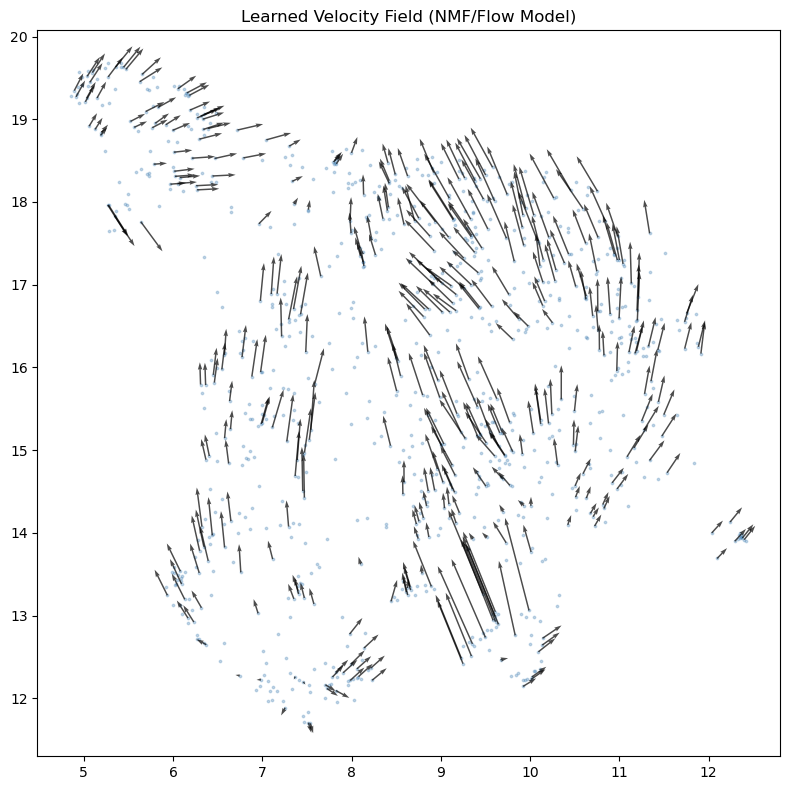

In [39]:
import numpy as np
import anndata as ad
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from umap import UMAP
from scipy.stats import spearmanr

%matplotlib inline

# Load data
adata = ad.read_h5ad(
    "/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline/velten_rna.h5ad"
)

V_pred = np.load("uv_leading_fixed_metrics/V_pred_learned.npy")   # <-- UPDATED NAME
A_genes = np.load("uv_leading_fixed_metrics/A_genes.npy", allow_pickle=True)

# Build mapping
gene_to_idx_full = {g: i for i, g in enumerate(adata.var_names)}

# Keep only genes present in adata
common_genes = [g for g in A_genes if g in gene_to_idx_full]

# Indices
gene_idx_full = np.array([gene_to_idx_full[g] for g in common_genes])
gene_idx_model = np.array([i for i, g in enumerate(A_genes) if g in gene_to_idx_full])

# Align
X = X_full[:, gene_idx_full]
V_pred = V_pred[:, gene_idx_model]

assert X.shape == V_pred.shape

# UMAP embedding
reducer = UMAP(n_neighbors=15, random_state=42)
X_umap = reducer.fit_transform(X)

# Project velocity to UMAP
eps = 0.5

X_perturbed = X + eps * V_pred
X_pert_umap = reducer.transform(X_perturbed)

V_umap_raw = (X_pert_umap - X_umap) / eps

# Smooth velocity field
nn = NearestNeighbors(n_neighbors=30).fit(X_umap)
_, idx = nn.kneighbors(X_umap)

V_umap_smooth = np.array([
    V_umap_raw[idx[i]].mean(axis=0)
    for i in range(len(X_umap))
])

# Plot vector field
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(
    X_umap[:, 0], X_umap[:, 1],
    s=3, alpha=0.3, c="steelblue"
)

sample = np.random.choice(len(X_umap), 400, replace=False)

ax.quiver(
    X_umap[sample, 0], X_umap[sample, 1],
    V_umap_smooth[sample, 0], V_umap_smooth[sample, 1],
    alpha=0.7, scale=10, width=0.002, color="black"
)

ax.set_title("Learned Velocity Field (NMF/Flow Model)")
plt.tight_layout()
plt.savefig("velocity_final.png", dpi=150)
plt.show()

## Step 9: CellOracle A comparison

In [40]:
co_A = np.load(f"{BASE}/cell_oracle_run/cell_oracle_global_A/A_celloracle.npy")
co_genes = np.load(f"{BASE}/cell_oracle_run/cell_oracle_global_A/A_genes.npy", allow_pickle=True).astype(str)
co_tfs = np.load(f"{BASE}/cell_oracle_run/cell_oracle_global_A/A_tfs.npy", allow_pickle=True).astype(str)

print("co_A shape:", co_A.shape)
print("len co_genes:", len(co_genes))
print("len co_tfs:", len(co_tfs))

# -----------------------------
# CORRECT ASSERTION
# -----------------------------
assert co_A.shape == (len(co_tfs), len(co_genes)), "TF × gene matrix expected"

# -----------------------------
# shared space
# -----------------------------
common_genes = sorted(set(A_genes) & set(co_genes))
common_tfs = sorted(set(A_tfs) & set(co_tfs))

assert len(common_genes) > 0 and len(common_tfs) > 0

pred_gene_to_idx = {g: i for i, g in enumerate(A_genes)}
pred_tf_to_idx = {t: i for i, t in enumerate(A_tfs)}

co_gene_to_idx = {g: i for i, g in enumerate(co_genes)}
co_tf_to_idx = {t: i for i, t in enumerate(co_tfs)}

pred_g_idx = np.array([pred_gene_to_idx[g] for g in common_genes])
pred_t_idx = np.array([pred_tf_to_idx[t] for t in common_tfs])

co_t_idx = np.array([co_tf_to_idx[t] for t in common_tfs])
co_g_idx = np.array([co_gene_to_idx[g] for g in common_genes])

# -----------------------------
# IMPORTANT: TRANSPOSE ALIGNMENT
# -----------------------------
# co_A is TF × gene, so we index [tf, gene]
A_co_aligned = co_A[np.ix_(co_t_idx, co_g_idx)]

# your model is gene × TF
A_pred_aligned = A_learned.detach().cpu().numpy()[np.ix_(pred_g_idx, pred_t_idx)]

# -----------------------------
# now compare properly
# -----------------------------
edge_metrics = edge_overlap_metrics(A_pred_aligned, A_co_aligned.T, frac=0.05)
tf_jaccard = mean_axis_jaccard(A_pred_aligned, A_co_aligned.T, axis=0, frac=0.1)
gene_jaccard = mean_axis_jaccard(A_pred_aligned, A_co_aligned.T, axis=1, frac=0.1)

print("\nCellOracle overlap metrics")
print(edge_metrics)
print(f"Mean TF-wise top-support Jaccard:   {tf_jaccard:.4f}")
print(f"Mean gene-wise top-support Jaccard: {gene_jaccard:.4f}")

# Optional: save these
celloracle_metrics = {
    **edge_metrics,
    "mean_tf_jaccard": tf_jaccard,
    "mean_gene_jaccard": gene_jaccard,
    "n_common_genes": len(common_genes),
    "n_common_tfs": len(common_tfs),
}
with open("uv_leading_fixed/celloracle_overlap_metrics.json", "w") as f:
    json.dump(celloracle_metrics, f, indent=2)


co_A shape: (277, 2995)
len co_genes: 2995
len co_tfs: 277

CellOracle overlap metrics
{'precision': 0.34189146838303275, 'recall': 0.34189146838303275, 'f1': 0.3418914633830328, 'jaccard': 0.20619366094792002, 'tp': 14182, 'pred_edges': 41481, 'ref_edges': 41481}
Mean TF-wise top-support Jaccard:   0.3419
Mean gene-wise top-support Jaccard: 0.3322


## Step 10: Stability of U/V via repeated NMF on final A

In [41]:
A_final = A_learned.detach().cpu().numpy()
A_pos = np.abs(A_final)  # NMF needs nonnegative input; abs is the simplest stable choice

NMF_RANK = min(20, min(A_pos.shape) - 1)  # adjust if you want a different interpretability rank
N_RUNS = 20
TOP_GENES = 25
TOP_TFS = 15

# reference decomposition
nmf_ref = NMF(
    n_components=NMF_RANK,
    init="nndsvda",
    random_state=0,
    max_iter=2000
)
W_ref = nmf_ref.fit_transform(A_pos)   # genes x r
H_ref = nmf_ref.components_            # r x tfs
ref_modules = module_sets_from_nmf(W_ref, H_ref, top_genes=TOP_GENES, top_tfs=TOP_TFS)

run_scores = []
run_gene_scores = []
run_tf_scores = []

for seed in range(1, N_RUNS + 1):
    nmf = NMF(
        n_components=NMF_RANK,
        init="nndsvda",
        random_state=seed,
        max_iter=2000
    )
    W = nmf.fit_transform(A_pos)
    H = nmf.components_
    cur_modules = module_sets_from_nmf(W, H, top_genes=TOP_GENES, top_tfs=TOP_TFS)

    match = match_module_sets(ref_modules, cur_modules)
    run_scores.append(match["mean_conservation"])

    # also track gene-only and TF-only conservation for a more interpretable number
    Sg = []
    St = []
    for (rg, rt), (cg, ct) in zip(ref_modules, cur_modules):
        Sg.append(jaccard(rg, cg))
        St.append(jaccard(rt, ct))
    run_gene_scores.append(float(np.mean(Sg)))
    run_tf_scores.append(float(np.mean(St)))

stability_results = {
    "nmf_rank": NMF_RANK,
    "n_runs": N_RUNS,
    "top_genes": TOP_GENES,
    "top_tfs": TOP_TFS,
    "mean_module_conservation": float(np.mean(run_scores)),
    "std_module_conservation": float(np.std(run_scores)),
    "mean_gene_conservation": float(np.mean(run_gene_scores)),
    "mean_tf_conservation": float(np.mean(run_tf_scores)),
}

print("\nNMF stability")
print(stability_results)

with open("uv_leading_fixed/nmf_stability.json", "w") as f:
    json.dump(stability_results, f, indent=2)



NMF stability
{'nmf_rank': 20, 'n_runs': 20, 'top_genes': 25, 'top_tfs': 15, 'mean_module_conservation': 1.0, 'std_module_conservation': 0.0, 'mean_gene_conservation': 1.0, 'mean_tf_conservation': 1.0}


In [34]:
from sklearn.decomposition import NMF
import torch.nn as nn

def top_edge_set(A, frac=0.05):
    A_flat = np.abs(np.asarray(A)).ravel()
    k      = max(1, int(np.ceil(frac * A_flat.size)))
    idx    = np.argpartition(A_flat, -k)[-k:]
    return set(idx.tolist())
 
def edge_jaccard(A1, A2, frac=0.05):
    s1, s2 = top_edge_set(A1, frac), top_edge_set(A2, frac)
    inter  = len(s1 & s2)
    union  = len(s1 | s2)
    return inter / union if union else 0.0
 
def train_once(seed=0, epochs=200):
    """Train a fresh model with a given random seed; return learned A."""
    torch.manual_seed(seed)
    np.random.seed(seed)
    m = RegulatoryFlowModel(G=G, T=T, K=K, M=M, P=P_np)
    o = torch.optim.Adam(m.parameters(), lr=1e-3)
    for _ in range(epochs):
        o.zero_grad()
        Vp, Vl, Al = m(X_TF_t)
        lo = (
            WEIGHTS["phase"]   * phase_prior_loss(Vl, phase_low_t, pair_conf_t) +
            WEIGHTS["attract"] * atac_attraction_loss(Vp, X_t, phase_t_t)       +
            WEIGHTS["cosine"]  * cosine_alignment_loss(Vl, X_low_t, nn_idx_t)  +
            WEIGHTS["smooth"]  * flow_smoothness_loss(Vl, nn_idx_t)             +
            WEIGHTS["sparse"]  * sparsity_loss(Al)                              +
            WEIGHTS["decor"]   * factor_decorrelation_loss(m)                   +
            WEIGHTS["vscale"]  * velocity_scale_loss(Vp, X_t)
        )
        lo.backward()
        torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)
        o.step()
    with torch.no_grad():
        _, _, A_out = m(X_TF_t)
    return A_out.detach().cpu().numpy()
 
print("\nRunning GRN bootstrap stability (5 seeds × 150 epochs)...")
A_runs = [train_once(seed=s, epochs=150) for s in range(1, 6)]
 
pairwise_j = [edge_jaccard(A_runs[i], A_runs[j], frac=0.05)
              for i in range(len(A_runs))
              for j in range(i + 1, len(A_runs))]
 
bootstrap_stability = {
    "mean_edge_jaccard":  float(np.mean(pairwise_j)),
    "std_edge_jaccard":   float(np.std(pairwise_j)),
    "n_pairs":            len(pairwise_j),
}
print("\nBootstrap GRN stability (TRAINING-level):")
print(bootstrap_stability)
 
# Also run NMF stability on the trained A (should now be <1.0 and meaningful)
def nmf_module_stability(A, n_components=20, top_genes=25, top_tfs=15, n_runs=10):
    A_pos   = np.abs(A)
    ref_nmf = NMF(n_components=n_components, init="nndsvda", random_state=0, max_iter=2000)
    W_ref   = ref_nmf.fit_transform(A_pos)
    H_ref   = ref_nmf.components_
    ref_mods = module_sets_from_nmf(W_ref, H_ref, top_genes, top_tfs)
 
    scores = []
    for seed in range(1, n_runs + 1):
        nmf = NMF(n_components=n_components, init="nndsvda",
                  random_state=seed, max_iter=2000)
        W   = nmf.fit_transform(A_pos)
        H   = nmf.components_
        cur = module_sets_from_nmf(W, H, top_genes, top_tfs)
        scores.append(match_module_sets(ref_mods, cur)["mean_conservation"])
 
    return {
        "mean_module_conservation": float(np.mean(scores)),
        "std_module_conservation":  float(np.std(scores)),
    }
 
nmf_stab = nmf_module_stability(A_np, n_components=20, top_genes=25, top_tfs=15, n_runs=10)
print("\nNMF module stability on learned A:")
print(nmf_stab)
 
stability_results = {**bootstrap_stability, **nmf_stab}
with open("uv_leading_fixed/stability_metrics.json", "w") as f:
    json.dump(stability_results, f, indent=2)


Running GRN bootstrap stability (5 seeds × 150 epochs)...

Bootstrap GRN stability (TRAINING-level):
{'mean_edge_jaccard': 0.8968280763526366, 'std_edge_jaccard': 0.016011848530710977, 'n_pairs': 10}

NMF module stability on learned A:
{'mean_module_conservation': 1.0, 'std_module_conservation': 0.0}


## Step 11: Pseudotime arrow agreement

In [42]:
pseudo = np.asarray(rna_adata.obs["facs_pseudotime"].values, dtype=float)
pseudo = pseudo[cell_idx]  # keep in sync with X / V_pred

# gene-space agreement
gene_arrow_metrics = pseudotime_arrow_agreement(
    X_space=X,
    V_pred=A_learned.detach().cpu().numpy() @ np.zeros((A_learned.shape[1], 1)).T if False else V_pred,
    pseudotime=pseudo,
    k=30
)

print("\nPseudotime arrow agreement in gene space")
print({k: v for k, v in gene_arrow_metrics.items() if k != "cosines"})

# UMAP-space agreement using your predicted velocities
reducer = UMAP(n_neighbors=15, random_state=42)
X_umap = reducer.fit_transform(X)

eps = 0.5
X_perturbed = X + eps * V_pred
X_pert_umap = reducer.transform(X_perturbed)
V_umap_raw = (X_pert_umap - X_umap) / eps

umap_arrow_metrics = pseudotime_arrow_agreement(
    X_space=X_umap,
    V_pred=V_umap_raw,
    pseudotime=pseudo,
    k=30
)

print("\nPseudotime arrow agreement in UMAP space")
print({k: v for k, v in umap_arrow_metrics.items() if k != "cosines"})

with open("uv_leading_fixed/pseudotime_arrow_metrics.json", "w") as f:
    json.dump(
        {
            "gene_space": {k: (float(v) if isinstance(v, (np.floating, float, int)) else v)
                           for k, v in gene_arrow_metrics.items() if k != "cosines"},
            "umap_space": {k: (float(v) if isinstance(v, (np.floating, float, int)) else v)
                           for k, v in umap_arrow_metrics.items() if k != "cosines"},
        },
        f,
        indent=2
    )


Pseudotime arrow agreement in gene space
{'mean_cosine': 0.005887746318071609, 'fraction_positive': 0.5064676616915423, 'n_valid': 1005}


/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



Pseudotime arrow agreement in UMAP space
{'mean_cosine': -0.07068172060916209, 'fraction_positive': 0.45084409136047665, 'n_valid': 1007}


## Step 12: Visualize velocity in PCA space

In [19]:
X_pca = adata.obsm["X_pca"][:, :10]  # use first PCs# linear projection of gene velocity into PCA space
V_pca = V_pred @ pca.components_.T[:, :10]
V_pca = -V_pca

from sklearn.neighbors import NearestNeighbors

nn = NearestNeighbors(n_neighbors=30).fit(X_pca)
_, idx = nn.kneighbors(X_pca)

V_pca_smooth = np.array([
    V_pca[idx[i]].mean(axis=0)
    for i in range(len(X_pca))
])

V_pca_smooth = V_pca_smooth / (np.linalg.norm(V_pca_smooth, axis=1, keepdims=True) + 1e-8)
V_pca_smooth *= 0.5

import numpy as np
import matplotlib.pyplot as plt

pseudo = adata.obs["facs_pseudotime"].values

fig, ax = plt.subplots(figsize=(15, 8))

sc = ax.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=pseudo,
    cmap="viridis",
    s=8,
    alpha=0.8
)

plt.colorbar(sc, ax=ax, label="FACS pseudotime")

sample = np.random.choice(len(X_pca), 400, replace=False)

ax.quiver(
    X_pca[sample, 0], X_pca[sample, 1],
    V_pca_smooth[sample, 0], V_pca_smooth[sample, 1],
    color="black", alpha=0.6, scale=20, width=0.002
)

ax.set_title("Velocity Field on PCA (Pseudotime-colored)")
plt.show()

NameError: name 'pca' is not defined

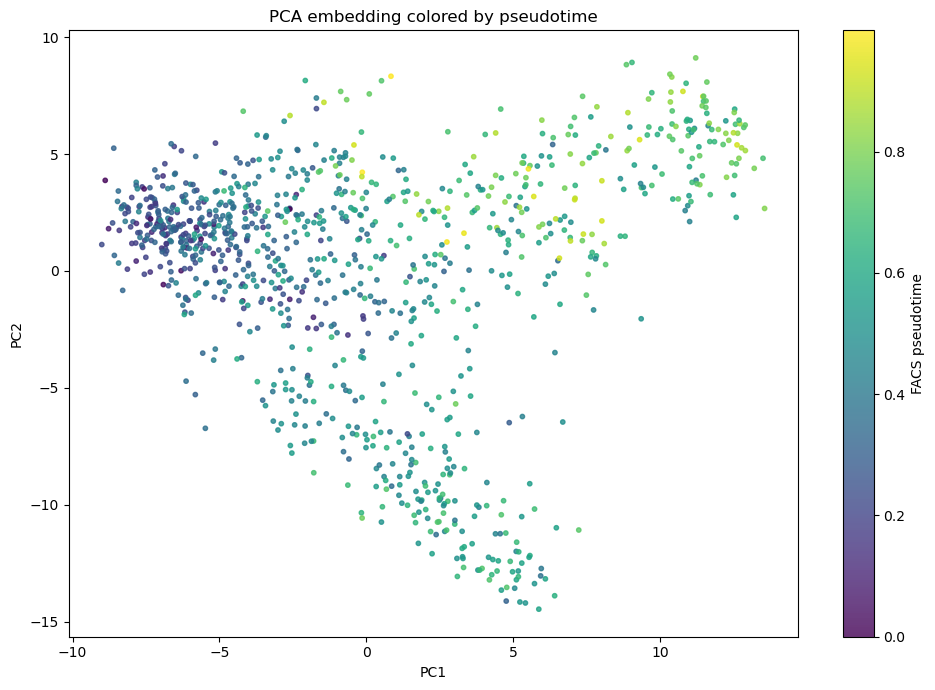

In [31]:
import numpy as np
import matplotlib.pyplot as plt

# PCA embedding
X_pca = adata.obsm["X_pca"][:, :2]

# pseudotime (or swap for any obs label)
pseudo = adata.obs["facs_pseudotime"].values

fig, ax = plt.subplots(figsize=(10, 7))

sc = ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=pseudo,
    cmap="viridis",
    s=10,
    alpha=0.8
)

plt.colorbar(sc, ax=ax, label="FACS pseudotime")

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("PCA embedding colored by pseudotime")

plt.tight_layout()
plt.show()